In [ ]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation
from quinex_application.visualisation.metadata_visualisation import VisualisationMetadata

c:\Users\m.gorres\AppData\Local\miniforge3\envs\quinex_application\lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

In [3]:
# Define continents
countries_by_continent = {
    "Africa": [
        "MZ","NE","NG","LY","MA","ML","MR","MW","NA","RW","ZA","ZM","TG","TD","BW","CD",
        "CF","CM","CI","DJ","DZ","EG","ET","GH","GM","GN","KE","LS","LR","SN","BJ",
        "MU","MZ","RE","SC","SD","SL","SO","SS","SZ","TZ","TN","UG","ZW",'BI',"BF"
    ],
    "Asia": [
        "AF","AM","AZ","BD","BT","BN","KH","CN","IN","ID","IR","IQ","IL","JP","JO",
        "KZ","KW","KG","LA","LB","MY","MV","MN","MM","NP","OM","PK","PS","PH","QA","SA","SG",
        "KR","LK","SY","TW","TJ","TH","TR","AE","UZ","VN","YE","HK","MO","BH","CV"
    ],
    "Europe": [
        "AL","AD","AT","BY","BE","BA","BG","HR","CY","CZ","DK","EE","FO","FI","FR","DE",
        "GR","HU","IS","IE","IT","LV","LT","LU","MK","MT","ME",
        "NL","NO","PL","PT","RO","RU","RS","SK","SI","ES","SE","CH","UA","GB","XK"
    ],
    "North America": [
        "BB","CA","CR","CU","DO","GL","JM","MX","NI","PA","PR","TT","US","GP"
    ]
}

def get_df_by_countries(metadata_df, quinex_df, country_codes):
    """
    Filter quinex_df for publications from one or multiple countries.

    country_codes: str or list[str]
    """
    # allow single country code as string
    if isinstance(country_codes, str):
        country_codes = [country_codes]

    pubs = metadata_df[
        metadata_df['countries'].apply(
            lambda x: any(code in x for code in country_codes)
        )
    ]

    dois = pubs['DOI'].tolist()
    return quinex_df[quinex_df['DOI'].isin(dois)]

## **Visualise Results**

### **Lifetime**

In [ ]:
metadata_df = visualisation.load_df("../data/quinex/df_quinex_metadata.parquet")
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
quinex_df = df[df["property_mapping"] == "Lifetime"]
quinex_df = quinex_df[quinex_df['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
quinex_df["unit_normalized"].value_counts()

In [ ]:
wind = quinex_df[quinex_df["entity_base_mapping"] == "Wind"]
pv = quinex_df[quinex_df["entity_base_mapping"] == "PV"]

print(f"Wind Efficiency entries: {len(wind)}")
print(f"PV Efficiency entries: {len(pv)}")

In [ ]:
# Wind Turbine Lifetime - with regional median overlay
data_wind = [
    {
        'df': wind,
        'df_region': [
            get_df_by_countries(metadata_df, wind, countries_by_continent["Europe"]), 
            get_df_by_countries(metadata_df, wind, countries_by_continent["Asia"]), 
            get_df_by_countries(metadata_df, wind, countries_by_continent["North America"])
            ],
        'region_labels': ['Europe', 'Asia', 'North America'],
        'value_col': 'value_normalized',
        'ylabel': 'Lifetime [Years]',
        'title': 'a',
        'xlabel': 'Wind Turbine'
    },
    {
    'df': pv,
    'df_region': [
        get_df_by_countries(metadata_df, pv, countries_by_continent["Europe"]), 
        get_df_by_countries(metadata_df, pv, countries_by_continent["Asia"]), 
        get_df_by_countries(metadata_df, pv, countries_by_continent["North America"])
        ],
    'region_labels': ['Europe', 'Asia', 'North America'],
    'value_col': 'value_normalized',
    'ylabel': 'Lifetime [Years]',
    'title': 'b',
    'xlabel': 'PV'
    }
]

fig, axes, stats = visualisation.plot_boxplot_with_regional_medians(
    data_wind,
    figsize=(6, 6),
    font_size=14,
    show_outliers=True,
    iqr_filter=True
)

fig.savefig("../data/figures/results/boxplot/lifetime_regional.pdf", bbox_inches='tight')

### **Efficiency**

In [ ]:
metadata_df = visualisation.load_df("../data/quinex/df_quinex_metadata.parquet")
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency_df = df[df["property_mapping"] == "Efficiency"]
efficiency_df = efficiency_df[efficiency_df['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency_df["unit_normalized"].value_counts()

In [ ]:
efficiency_df["entity_base_mapping"].value_counts()

In [ ]:
# Split by technology
wind = efficiency_df[efficiency_df["entity_base_mapping"] == "Wind"]
pv = efficiency_df[efficiency_df["entity_base_mapping"] == "PV"]
battery = efficiency_df[efficiency_df["entity_base_mapping"] == "Battery"]
hydrogen = efficiency_df[efficiency_df["entity_base_mapping"] == "Hydrogen"]
electrolyzer = efficiency_df[efficiency_df["entity_base_mapping"] == "Electrolyzer"]

print(f"Wind Efficiency entries: {len(wind)}")
print(f"PV Efficiency entries: {len(pv)}")
print(f"Battery Efficiency entries: {len(battery)}")
print(f"Hydrogen Efficiency entries: {len(hydrogen)}")
print(f"Electrolyzer Efficiency entries: {len(electrolyzer)}")

In [ ]:
# Efficiency Visualization - with regional median overlay
data_efficiency = [
    {
        'df': wind,
        'df_region': [
            get_df_by_countries(metadata_df, wind, countries_by_continent["Europe"]), 
            get_df_by_countries(metadata_df, wind, countries_by_continent["Asia"]), 
            get_df_by_countries(metadata_df, wind, countries_by_continent["North America"])
            ],
        'region_labels': ['Europe', 'Asia', 'North America'],
        'value_col': 'value_normalized',
        'ylabel': 'Efficiency [%]',
        'title': 'a',
        'xlabel': 'Wind'
    },
    {
    'df': pv,
    'df_region': [
        get_df_by_countries(metadata_df, pv, countries_by_continent["Europe"]), 
        get_df_by_countries(metadata_df, pv, countries_by_continent["Asia"]), 
        get_df_by_countries(metadata_df, pv, countries_by_continent["North America"])
        ],
    'region_labels': ['Europe', 'Asia', 'North America'],
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]',
    'title': 'b',
    'xlabel': 'PV'
    },
    {
    'df': battery,
    'df_region': [
        get_df_by_countries(metadata_df, battery, countries_by_continent["Europe"]), 
        get_df_by_countries(metadata_df, battery, countries_by_continent["Asia"]), 
        get_df_by_countries(metadata_df, battery, countries_by_continent["North America"])
        ],
    'region_labels': ['Europe', 'Asia', 'North America'],
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]',
    'title': 'c',
    'xlabel': 'Battery'
    },
    {          
    'df': electrolyzer,
    'df_region': [
        get_df_by_countries(metadata_df, electrolyzer, countries_by_continent["Europe"]), 
        get_df_by_countries(metadata_df, electrolyzer, countries_by_continent["Asia"]), 
        get_df_by_countries(metadata_df, electrolyzer, countries_by_continent["North America"])
        ],
    'region_labels': ['Europe', 'Asia', 'North America'],
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]',
    'title': 'd',
    'xlabel': 'Electrolyzer'
    },
    {
    'df': hydrogen,
    'df_region': [
        get_df_by_countries(metadata_df, hydrogen, countries_by_continent["Europe"]), 
        get_df_by_countries(metadata_df, hydrogen, countries_by_continent["Asia"]), 
        get_df_by_countries(metadata_df, hydrogen, countries_by_continent["North America"])
        ],
    'region_labels': ['Europe', 'Asia', 'North America'],
    'value_col': 'value_normalized',
    'ylabel': 'Efficiency [%]',
    'title': 'e',
    'xlabel': 'Hydrogen'
    }
]

fig, axes, stats = visualisation.plot_boxplot_with_regional_medians(
    data_efficiency,
    figsize=(10, 6),
    font_size=14,
    show_outliers=True,
    iqr_filter=True,
    ncols=3
)

fig.savefig("../data/figures/results/boxplot/efficiency_regional.pdf", bbox_inches='tight')

### **LCOE**

In [ ]:
metadata_df = visualisation.load_df("../data/quinex/df_quinex_metadata.parquet")
lcoe_df = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe2024.xlsx")

lcoe_df["unit_normalized"].value_counts()

📂 Loaded DataFrame from '../data/quinex/df_quinex_metadata.parquet' with 31653 rows


unit_normalized
[('$', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('kWh', -1.0, 'http://qudt.org/vocab/unit/KiloW-HR', None)]         2076
[('USD', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('kWh', -1.0, 'http://qudt.org/vocab/unit/KiloW-HR', None)]        308
[('€', 1.0, 'http://qudt.org/vocab/currency/EUR', None), ('MWh', -1.0, 'http://qudt.org/vocab/unit/MegaW-HR', None)]          217
[('€', 1.0, 'http://qudt.org/vocab/currency/EUR', None), ('kWh', -1.0, 'http://qudt.org/vocab/unit/KiloW-HR', None)]          184
[('$', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('MWh', -1.0, 'http://qudt.org/vocab/unit/MegaW-HR', None)]          158
                                                                                                                             ... 
[('A$', 1.0, 'http://qudt.org/vocab/currency/AUD', None), ('MWh', -1.0, 'http://qudt.org/vocab/unit/MegaW-HR', None)]           1
[('Dollar', 1.0, 'http://qudt.org/vocab/currency/USD', None), ('kWh', -1.0

In [5]:
lcoe_df["entity_base_mapping"].value_counts()

entity_base_mapping
PV                      1500
Wind Turbine             811
Hybrid Energy System     519
Battery                  289
Hydrogen                 229
Coal                      54
Natural Gas               36
Electrolyzer              32
Name: count, dtype: int64

In [6]:
# Split by technology
wind_lcoe = lcoe_df[lcoe_df["entity_base_mapping"] == "Wind Turbine"]
pv_lcoe = lcoe_df[lcoe_df["entity_base_mapping"] == "PV"]
battery_lcoe = lcoe_df[lcoe_df["entity_base_mapping"] == "Battery"]

print(f"Wind LCOE entries: {len(wind_lcoe)}")
print(f"PV LCOE entries: {len(pv_lcoe)}")
print(f"Battery LCOE entries: {len(battery_lcoe)}")

Wind LCOE entries: 811
PV LCOE entries: 1500
Battery LCOE entries: 289


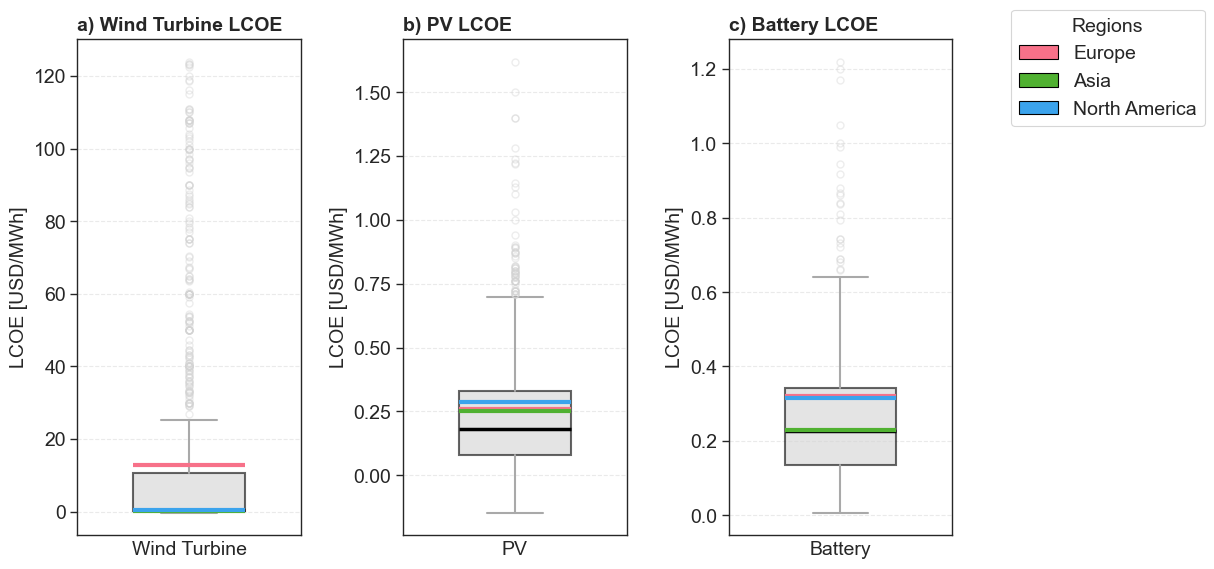

In [10]:
# LCOE Visualization - with regional median overlay
data_lcoe = [
    {
        'df': wind_lcoe,
        'df_region': [
            get_df_by_countries(metadata_df, wind_lcoe, countries_by_continent["Europe"]), 
            get_df_by_countries(metadata_df, wind_lcoe, countries_by_continent["Asia"]), 
            get_df_by_countries(metadata_df, wind_lcoe, countries_by_continent["North America"])
            ],
        'region_labels': ['Europe', 'Asia', 'North America'],
        'value_col': 'value_normalized',
        'ylabel': 'LCOE [USD/MWh]',
        'title': 'a',
        'xlabel': 'Wind Turbine'
    },
    {
    'df': pv_lcoe,
    'df_region': [
        get_df_by_countries(metadata_df, pv_lcoe, countries_by_continent["Europe"]), 
        get_df_by_countries(metadata_df, pv_lcoe, countries_by_continent["Asia"]), 
        get_df_by_countries(metadata_df, pv_lcoe, countries_by_continent["North America"])
        ],
    'region_labels': ['Europe', 'Asia', 'North America'],
    'value_col': 'value_normalized',
    'ylabel': 'LCOE [USD/MWh]',
    'title': 'b',
    'xlabel': 'PV'
    },
    {
    'df': battery_lcoe,
    'df_region': [
        get_df_by_countries(metadata_df, battery_lcoe, countries_by_continent["Europe"]), 
        get_df_by_countries(metadata_df, battery_lcoe, countries_by_continent["Asia"]), 
        get_df_by_countries(metadata_df, battery_lcoe, countries_by_continent["North America"])
        ],
    'region_labels': ['Europe', 'Asia', 'North America'],
    'value_col': 'value_normalized',
    'ylabel': 'LCOE [USD/MWh]',
    'title': 'c',
    'xlabel': 'Battery'
    }
]

fig, axes, stats = visualisation.plot_boxplot_with_regional_medians(
    data_lcoe,
    figsize=(10, 6),
    font_size=14,
    show_outliers=True,
    iqr_filter=True,
    ncols=3
)

fig.savefig("../data/figures/results/boxplot/lcoe_regional.pdf", bbox_inches='tight')